# Logical Bell-pair distillation: rates before numerics

Two ways to make a logical Bell pair $|\Phi^+_L\rangle$ with `build_surgery_bell_prep_fusion_zigzag` (ZZ merge of two $|+_L\rangle$ patches across a phase-1 zigzag seam, every split generator joined by a Bell pair from two emissions and a photon fusion):

* **A — physical post-selection.** A fusion that fails is discarded and retried until it succeeds; the surgery only uses complete Bell pairs.
* **B — logical post-selection.** Each fusion is attempted once. A failed fusion still measures one of its two parities (the other is an erasure); a lost one measures neither. Decode, and accept the whole preparation only if the erasures leave no logical ambiguity, $k(E)=0$.

With fusion failure as the only noise both strategies give fidelity 1, so the comparison is purely a rate. This notebook sets up the rate bookkeeping for both strategies. The one unknown, B's acceptance $A_d = \Pr[k(E)=0]$, comes from the numerics in the next step; here it is a free parameter, and we compute the break-even $A_d^*$ that B has to beat under each cost model.

In [1]:
%matplotlib inline
import collections

import matplotlib.pyplot as plt
import numpy as np

from dizx.builders import build_surgery_bell_prep_fusion_zigzag, surgery_layers

## 1. Fusion channel

Per fusion: loss with probability $\ell$ (both outcomes erased); otherwise failure with probability $f$ (one outcome erased, $XX$ or $ZZ$ with equal probability), otherwise success. Unboosted linear-optics fusion has $f = 1/2$.

| event | probability |
|---|---|
| success | $s = (1-\ell)(1-f)$ |
| only $XX$ erased | $a = (1-\ell)f/2$ |
| only $ZZ$ erased | $a$ |
| both erased | $\ell$ |

The marginal erasure rate of one outcome is $q = \ell + a$, so $q = 1/4$ at $f=1/2,\ \ell=0$. Strategy A sees every fusion through $s$ alone; strategy B sees the full table.

In [2]:
def fusion_channel(f: float = 0.5, loss: float = 0.0) -> dict[str, float]:
    # Probabilities of the four herald events of one fusion, and q.
    s = (1 - loss) * (1 - f)
    a = (1 - loss) * f / 2
    return {"s": s, "a": a, "loss": loss, "q": loss + a}


fusion_channel(), fusion_channel(0.5, 0.05)

({'s': 0.5, 'a': 0.25, 'loss': 0.0, 'q': 0.25},
 {'s': 0.475, 'a': 0.2375, 'loss': 0.05, 'q': 0.2875})

## 2. How many fusions, and when

Read the fusions off the built experiment and group them by merge layer (their time coordinate). The merge has $2n+1$ layers, starting and ending with the joint's type ($ZZ$); a $ZZ$ layer has $d$ split generators on the zigzag and an $XX$ layer $d-1$. So

$$N(d, n) = (n+1)\,d + n\,(d-1), \qquad N(d, d) = 2d^2,$$

which is the $N = 2d^2$ of the draft when $n = d$.

In [3]:
def fusion_layers(d: int, n: int) -> list[int]:
    # Number of fusions in each merge layer, in time order.
    exp = build_surgery_bell_prep_fusion_zigzag(d, n).experiment
    ts = collections.Counter(exp.positions[l.interaction.ends[0]][2]
                             for l in exp.links if l.kind == "fusion")
    return [ts[t] for t in sorted(ts)]


for d in (3, 5, 7):
    for n in (1, 2, d):
        m = fusion_layers(d, n)
        assert len(m) == surgery_layers(n)[1]
        assert sum(m) == (n + 1) * d + n * (d - 1)
        print(f"d={d} n={n}: layers {m}, N={sum(m)}")

d=3 n=1: layers [3, 2, 3], N=8
d=3 n=2: layers [3, 2, 3, 2, 3], N=13


d=3 n=3: layers [3, 2, 3, 2, 3, 2, 3], N=18
d=5 n=1: layers [5, 4, 5], N=14


d=5 n=2: layers [5, 4, 5, 4, 5], N=23


d=5 n=5: layers [5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5], N=50


d=7 n=1: layers [7, 6, 7], N=20


d=7 n=2: layers [7, 6, 7, 6, 7], N=33


d=7 n=7: layers [7, 6, 7, 6, 7, 6, 7, 6, 7, 6, 7, 6, 7, 6, 7], N=98


From here on use the closed form, so large $d$ doesn't need a build.

In [4]:
def layer_sizes(d: int, n: int) -> list[int]:
    # Fusions per merge layer: d on ZZ layers, d - 1 on XX layers.
    return [d if i % 2 == 0 else d - 1 for i in range(2 * n + 1)]


assert all(layer_sizes(d, n) == fusion_layers(d, n) for d in (3, 5) for n in (1, 2, 3))

## 3. Cost models

Time unit: one fusion attempt, $\tau = 1$. Each code layer also costs $t_r$ of local operations (syndrome extraction), the same in both strategies. The patches run $2n$ layers before the merge and $2n-1$ after it. Each link has its own emitter pair, so links in one layer are attempted in parallel.

**Raw attempts per accepted pair** (resource count; the draft's $G_\text{res}$):
$$C_A = N/s, \qquad C_B = N/A_d, \qquad G_\text{res} = A_d/s .$$

**Batch, no retries.** A attempts all $N$ fusions once and needs every one to succeed: acceptance $s^N$. This is the fairest *like-for-like* version of physical post-selection (same hardware time per attempt as B), and B wins whenever $A_d > s^N$, which is almost always.

**Synchronous rounds with retries** (the natural schedule for A). Merge layer $t$ cannot start its local gates until all of its $m_t$ Bell pairs exist. With independent retries per link, the wait is the maximum $M_{m}$ of $m_t$ geometric variables with success $s$:
$$\mathbb E[M_m] = \sum_{k\ge 0}\Big[1-\big(1-(1-s)^k\big)^m\Big] \approx \frac{\ln m}{\ln\frac{1}{1-s}} + O(1).$$
So
$$T_A = (6n)\,t_r + \sum_t \mathbb E[M_{m_t}], \qquad T_B = \frac{(4n+1)\,t_r + (2n+1)}{A_d} + (2n-1)\,t_r .$$
B rejects as soon as the merge heralds are in ($k(E)$ depends only on the erasure support), so a rejected attempt costs the pre-merge and merge layers; the post-merge layers are paid once. Local ops are noiseless here, so the patches are reprepared fresh on each restart.

**All links up front.** A variant with memories: every link is attempted in parallel before the merge and held. A then waits $\mathbb E[M_N]$ instead of $\sum_t \mathbb E[M_{m_t}]$, and B's single attempt costs one slot instead of $2n+1$.

In [5]:
def expected_max_geometric(m: int, s: float, tol: float = 1e-15) -> float:
    # E[max of m iid Geometric(s)] on {1, 2, ...}.
    if s >= 1:
        return 1.0
    total, k = 0.0, 0
    while True:
        term = 1 - (1 - (1 - s) ** k) ** m
        total += term
        if term < tol:
            return total
        k += 1


def attempts_A(d, n, s):
    # Raw fusion attempts per accepted pair, physical retries.
    return sum(layer_sizes(d, n)) / s


def attempts_B(d, n, A):
    # Raw fusion attempts per accepted pair, logical post-selection.
    return sum(layer_sizes(d, n)) / A


def time_A(d, n, s, t_r, upfront=False):
    # Time per accepted pair, physical retries in synchronous rounds.
    m = layer_sizes(d, n)
    wait = (expected_max_geometric(sum(m), s) if upfront
            else sum(expected_max_geometric(k, s) for k in m))
    return 6 * n * t_r + wait


def time_B(d, n, A, t_r, upfront=False):
    # Time per accepted pair, one attempt per link, restart on k(E) > 0.
    fusions = 1 if upfront else 2 * n + 1
    return ((4 * n + 1) * t_r + fusions) / A + (2 * n - 1) * t_r


def breakeven_A(d, n, s, t_r, model):
    # Acceptance A_d at which B matches A under `model`.
    if model == "attempts":
        return s
    if model == "batch":
        return s ** sum(layer_sizes(d, n))
    upfront = model == "time_upfront"
    # time_B(A) = time_A  =>  A = (time_B(1) - post) / (time_A - post), post = (2n - 1) t_r
    post = (2 * n - 1) * t_r
    return (time_B(d, n, 1, t_r, upfront) - post) / (time_A(d, n, s, t_r, upfront) - post)

Sanity checks: one link is a plain geometric, mean $1/s$; with $s=1$ the strategies coincide ($A^*=1$ in every model); and the Monte Carlo maximum agrees with the series.

In [6]:
rng = np.random.default_rng(0)
assert np.isclose(expected_max_geometric(1, 0.5), 2)
assert np.isclose(expected_max_geometric(7, 0.5), rng.geometric(0.5, (200_000, 7)).max(1).mean(), rtol=1e-2)
for model in ("attempts", "batch", "time", "time_upfront"):
    assert np.isclose(breakeven_A(5, 5, 1.0, 3.0, model), 1)

## 4. Break-even acceptance at $f = 1/2$, no loss

$s = 1/2$. Break-even $A_d^*$ for each model, $n = d$, with local layer time $t_r$ in units of a fusion attempt. B gives a rate advantage wherever the actual $A_d$ (next step) is above $A_d^*$.

In [7]:
s = fusion_channel(0.5, 0.0)["s"]
models = {"attempts": "raw attempts", "time": "time, per-layer retries",
          "time_upfront": "time, all links up front"}
print(f"{'d':>3} {'N':>5}  {'batch s^N':>10}  " + "  ".join(f"{k:>12}" for k in models))
for t_r in (0.0, 1.0, 10.0):
    print(f"t_r = {t_r}")
    for d in (3, 5, 7, 9, 11, 15):
        row = [breakeven_A(d, d, s, t_r, m) for m in models]
        print(f"{d:>3} {2*d*d:>5}  {s**(2*d*d):>10.2e}  " + "  ".join(f"{a:>12.4f}" for a in row))

  d     N   batch s^N      attempts          time  time_upfront
t_r = 0.0
  3    18    3.81e-06        0.5000        0.3403        0.1804
  5    50    8.88e-16        0.5000        0.2730        0.1430
  7    98    3.16e-30        0.5000        0.2413        0.1257
  9   162    1.71e-49        0.5000        0.2220        0.1152
 11   242    1.41e-73        0.5000        0.2086        0.1081
 15   450   3.44e-136        0.5000        0.1908        0.0985
t_r = 1.0
  3    18    3.81e-06        0.5000        0.5957        0.7550
  5    50    8.88e-16        0.5000        0.5221        0.7860
  7    98    3.16e-30        0.5000        0.4826        0.8118
  9   162    1.71e-49        0.5000        0.4568        0.8319
 11   242    1.41e-73        0.5000        0.4380        0.8479
 15   450   3.44e-136        0.5000        0.4117        0.8714
t_r = 10.0
  3    18    3.81e-06        0.5000        0.9099        0.9665
  5    50    8.88e-16        0.5000        0.8830        0.9724
  7    98

In the time models, A's per-layer wait is about $\log_2 m_t + 1.3$ attempts while B's is one, so A's merge costs $\sim(2n+1)\log_2 d$ against B's $2n+1$. The break-even therefore *falls* with $d$ when fusion time dominates ($t_r \to 0$), while the true $A_d$ rises toward 1 below the percolation threshold. Large $t_r$ hides the difference: A's retry wait becomes negligible next to the local layers, while every B rejection repeats $(4n+1)$ of them, so $A^*\to 1$. Holding all links up front helps A more than B (A's wait drops from $\sum_t\mathbb E[M_{m_t}]$ to $\mathbb E[M_N]$, B's from $2n+1$ to $1$), so that schedule needs a higher $A_d$ once $t_r \gtrsim 1$.

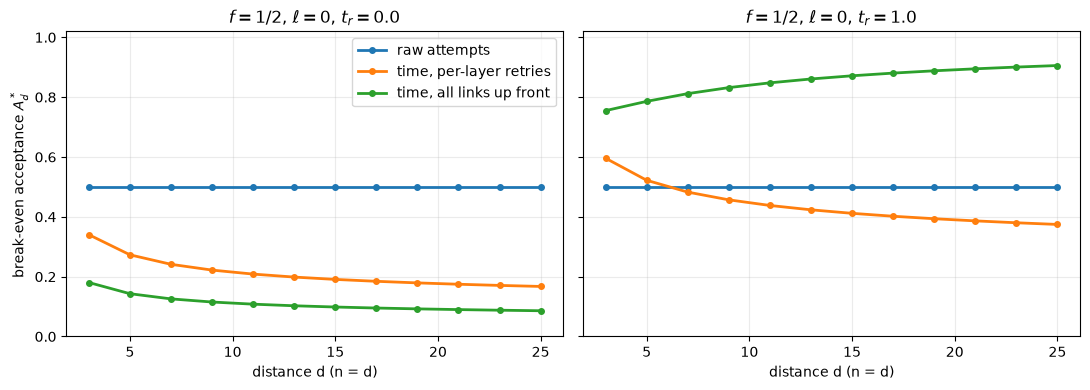

In [8]:
ds = np.arange(3, 26, 2)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, t_r in zip(axes, (0.0, 1.0)):
    for model, label in models.items():
        ax.plot(ds, [breakeven_A(d, d, s, t_r, model) for d in ds], "o-", ms=4, lw=2, label=label)
    ax.set(xlabel="distance d (n = d)", title=f"$f=1/2$, $\\ell=0$, $t_r={t_r}$", ylim=(0, 1.02))
    ax.grid(alpha=0.25)
axes[0].set_ylabel("break-even acceptance $A_d^*$")
axes[0].legend()
fig.tight_layout()

## 5. Dependence on local layer time

Break-even vs $t_r$ for the per-layer schedule. As $t_r\to\infty$ every curve tends to 1: A's wait is negligible next to the local layers, and B's restarts repeat $4n+1$ of them. The advantage regime is fusion-time-limited operation, $t_r \lesssim 1$.

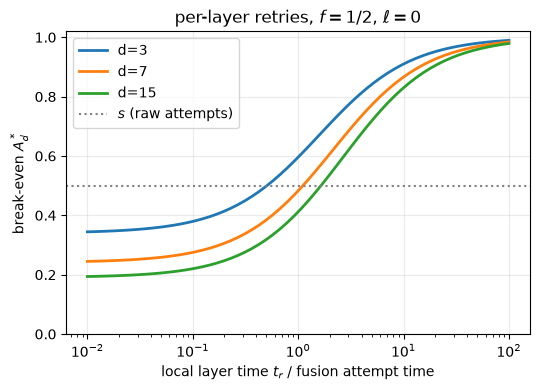

In [9]:
t_rs = np.logspace(-2, 2, 60)
fig, ax = plt.subplots(figsize=(5.5, 4))
for d in (3, 7, 15):
    ax.plot(t_rs, [breakeven_A(d, d, s, t, "time") for t in t_rs], lw=2, label=f"d={d}")
ax.axhline(s, color="0.5", ls=":", lw=1.5, label="$s$ (raw attempts)")
ax.set(xscale="log", xlabel="local layer time $t_r$ / fusion attempt time",
       ylabel="break-even $A_d^*$", ylim=(0, 1.02), title="per-layer retries, $f=1/2$, $\\ell=0$")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()

## 6. Gain as a function of the (unknown) acceptance

Rate gain $G = T_A/T_B$ (time) and $G_\text{res} = A_d/s$ (attempts) against $A_d$, at $d=7$. The numerics will place a point on each curve.

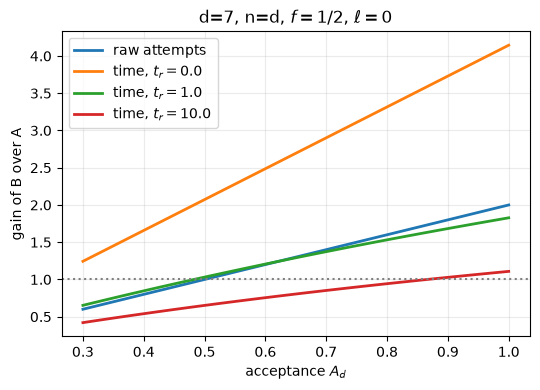

In [10]:
d, As = 7, np.linspace(0.3, 1, 100)
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(As, As / s, lw=2, label="raw attempts")
for t_r in (0.0, 1.0, 10.0):
    ax.plot(As, [time_A(d, d, s, t_r) / time_B(d, d, A, t_r) for A in As], lw=2, label=f"time, $t_r={t_r}$")
ax.axhline(1, color="0.5", ls=":", lw=1.5)
ax.set(xlabel="acceptance $A_d$", ylabel="gain of B over A", title=f"d={d}, n=d, $f=1/2$, $\\ell=0$")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()

## 7. Loss

Loss lowers $s$ for A and raises the both-erased weight for B. Break-even $A_d^*$ vs $\ell$ at $f=1/2$, $d=7$. (The asymptotic condition for $A_d\to1$ is $q<1/2$, i.e. $\ell < 1/3$ at $f = 1/2$, assuming the interface sectors are square-lattice bond percolation.)

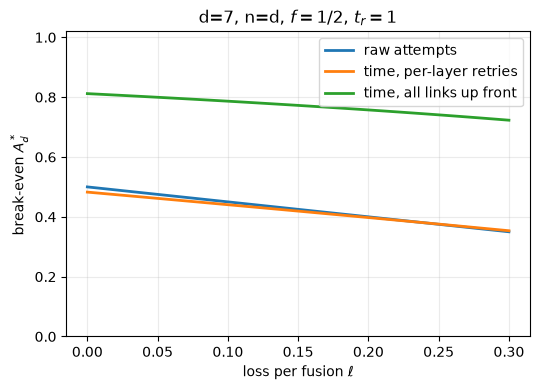

In [11]:
losses = np.linspace(0, 0.3, 31)
fig, ax = plt.subplots(figsize=(5.5, 4))
for model, label in models.items():
    ax.plot(losses, [breakeven_A(7, 7, fusion_channel(0.5, l)["s"], 1.0, model) for l in losses],
            lw=2, label=label)
ax.set(xlabel="loss per fusion $\\ell$", ylabel="break-even $A_d^*$", ylim=(0, 1.02),
       title="d=7, n=d, $f=1/2$, $t_r=1$")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()

# Part II: estimating $A_d$

## 8. Fusion outcomes as DEM columns

With ideal local operations, only the fusion outcomes can be wrong. Flipping a measurement record flips exactly the detectors and observables that include it, so each fusion outcome's column can be read straight from the circuit's `DETECTOR`/`OBSERVABLE_INCLUDE` targets. Each fusion is `CX c t` (tag `fusion_gate`), then `MX c` (the $XX$ outcome) and `M t` (the $ZZ$ outcome).

The ZZ-observable ($\bar Z\bar Z$, the merge outcome) and XX-observable ($\bar X\bar X$) builds differ only in the final patch readout, so they are two views of the same fusions. The pair is accepted only if both labels are determined.

In [12]:
import functools
import json

MEASUREMENTS = {"M", "MX", "MY", "MR", "MRX", "MRY"}


def fusion_columns(circuit):
    # Per fusion, in circuit order: (t, c, t-qubit, [XX column, ZZ column]),
    # a column being (detectors flipped, observable flipped).
    pending, fusions, rec = {}, [], 0
    for inst in circuit.flattened():
        tag = json.loads(inst.tag) if inst.tag else {}
        if tag.get("operation") == "fusion_gate":
            qs = [q.value for q in inst.targets_copy()]
            for c, t in zip(qs[::2], qs[1::2]):
                pending[c], pending[t] = (len(fusions), 0), (len(fusions), 1)
                fusions.append((tag["t"], c, t, [None, None]))
        if inst.name in MEASUREMENTS:
            for q in inst.targets_copy():
                if tag.get("operation") == "fusion_measurement":
                    k, slot = pending.pop(q.value)
                    assert ("XX", "ZZ")[slot] == tag["basis"]
                    fusions[k][3][slot] = rec
                rec += 1
        else:
            assert not inst.name.startswith("M") or inst.name == "MPAD", inst.name
    assert not pending and rec == circuit.num_measurements

    dets, obs = collections.defaultdict(set), collections.defaultdict(int)
    rec = det = 0
    for inst in circuit.flattened():
        if inst.name in MEASUREMENTS:
            rec += len(inst.targets_copy())
        elif inst.name == "DETECTOR":
            for t in inst.targets_copy():
                dets[rec + t.value].add(det)
            det += 1
        elif inst.name == "OBSERVABLE_INCLUDE":
            for t in inst.targets_copy():
                obs[rec + t.value] ^= 1
    return [(t, c, q, [(frozenset(dets[r]), obs[r]) for r in recs]) for t, c, q, recs in fusions]


@functools.cache
def interface(d: int, n: int, observable: str):
    return fusion_columns(build_surgery_bell_prep_fusion_zigzag(d, n, observable=observable).circuit)

Invariants, before trusting any number:

* one fusion per Bell pair, $N = 2d^2$ at $n=d$;
* the same fusions, in the same order, in both builds;
* every outcome flips at most two detectors (graph-like), so the interface is a matching graph with one boundary node;
* each observable is carried by one outcome type only: $d$ $ZZ$ outcomes for $\bar Z\bar Z$ and $d+1$ $XX$ outcomes for $\bar X\bar X$. That is the cut size of the chosen representative, not the distance.

In [13]:
for d in (3, 5, 7):
    zz, xx = interface(d, d, "ZZ"), interface(d, d, "XX")
    assert len(zz) == 2 * d * d
    assert [f[:3] for f in zz] == [f[:3] for f in xx]
    for fus, cut in ((zz, {1: d}), (xx, {0: d + 1})):
        assert all(len(col[0]) <= 2 for f in fus for col in f[3])
        flips = collections.Counter(s for f in fus for s, col in enumerate(f[3]) if col[1])
        assert flips == cut, flips
print("ok")

ok


## 9. Ambiguity test

At $p=0$ the unerased outcomes are known exactly, so a logical label is undetermined iff some erased edge set is undetectable and flips it, $k(E)=1$. On a graph that means an erased cycle with odd observable parity, where degree-1 columns end on the boundary node. A union-find that carries each node's parity relative to its root finds such a cycle in near-linear time. Below it is checked against the rank test $k(E) = \mathrm{rank}\binom{H_E}{L_E} - \mathrm{rank}\,H_E$ on random patterns.

In [14]:
BOUNDARY = -1


def edges(fus):
    # Per fusion, its two outcomes as (u, v, observable bit).
    return [[(*sorted(dets), *[BOUNDARY] * (2 - len(dets)), o) for dets, o in f[3]] for f in fus]


def ambiguous(erased) -> bool:
    # True iff the erased edges close a cycle with odd observable parity.
    parent, parity = {}, {}

    def find(x):
        p = 0
        while parent.get(x, x) != x:
            p ^= parity[x]
            x = parent[x]
        return x, p

    for u, v, o in erased:
        (ru, pu), (rv, pv) = find(u), find(v)
        if ru == rv:
            if pu ^ pv ^ o:
                return True
        else:
            parent[ru], parity[ru] = rv, pu ^ pv ^ o
    return False


def gf2_rank(M):
    M, r = M.copy(), 0
    for c in range(M.shape[1]):
        rows = np.nonzero(M[r:, c])[0]
        if len(rows) == 0:
            continue
        M[[r, r + rows[0]]] = M[[r + rows[0], r]]
        others = np.nonzero(M[:, c])[0]
        M[others[others != r]] ^= M[r]
        r += 1
        if r == M.shape[0]:
            break
    return r


def k_rank(cols) -> int:
    if not cols:
        return 0
    rows = sorted(set().union(*(dets for dets, _ in cols)))
    H = np.zeros((len(rows) + 1, len(cols)), np.uint8)
    for j, (dets, o) in enumerate(cols):
        H[[rows.index(x) for x in dets], j] = 1
        H[-1, j] = o
    return gf2_rank(H) - gf2_rank(H[:-1])


rng = np.random.default_rng(1)
for d in (3, 5):
    for obs in ("ZZ", "XX"):
        fus = interface(d, d, obs)
        E = edges(fus)
        for _ in range(300):
            mask = rng.random((len(fus), 2)) < 0.3
            picks = [(i, s) for i in range(len(fus)) for s in (0, 1) if mask[i, s]]
            assert ambiguous([E[i][s] for i, s in picks]) == (k_rank([fus[i][3][s] for i, s in picks]) == 1)
print("union-find agrees with the rank test")

union-find agrees with the rank test


## 10. Sampling the correlated herald channel

Per fusion: success $s$, $XX$ only erased $a$, $ZZ$ only erased $a$, both erased $\ell$ (§1). The same herald pattern is applied to both builds. A shot is accepted iff neither label is ambiguous, $A_d = \Pr[k_Z = k_X = 0]$. The per-sector acceptances are also recorded, to see how they combine.

In [15]:
def sample_acceptance(d: int, n: int, f: float, loss: float, shots: int, seed: int = 0):
    # Fractions accepted: (both labels, ZZ label, XX label).
    ch = fusion_channel(f, loss)
    E = {obs: edges(interface(d, n, obs)) for obs in ("ZZ", "XX")}
    N = len(E["ZZ"])
    # event per fusion: 0 success, 1 XX erased, 2 ZZ erased, 3 both
    cdf = np.cumsum([ch["s"], ch["a"], ch["a"]])
    events = np.searchsorted(cdf, np.random.default_rng(seed).random((shots, N)), side="right")
    ok = np.zeros((shots, 2), bool)
    for shot, ev in enumerate(events):
        for j, (obs, slot) in enumerate((("ZZ", 1), ("XX", 0))):
            ok[shot, j] = not ambiguous([E[obs][i][s] for i in np.nonzero(ev)[0]
                                         for s in (0, 1) if ev[i] in (s + 1, 3)])
    return ok.all(1).mean(), ok[:, 0].mean(), ok[:, 1].mean()


def stderr(a, shots):
    return np.sqrt(a * (1 - a) / shots)

### Unboosted fusion, no loss ($f=1/2$, $\ell = 0$, so $s = 1/2$, $q = 1/4$)

The draft's union-bound certificates are $\underline A_3 = 0.837$ and $\underline A_5 = 0.958$, and the estimates must sit above them.

In [16]:
SHOTS = 20_000
acc = {}
for d in (3, 5, 7, 9):
    acc[d] = sample_acceptance(d, d, 0.5, 0.0, SHOTS, seed=d)
    a, az, ax_ = acc[d]
    print(f"d={d}: A_d = {a:.4f} ± {stderr(a, SHOTS):.4f}   "
          f"(ZZ label {az:.4f}, XX label {ax_:.4f}, product {az * ax_:.4f})")
assert acc[3][0] > 0.8373 and acc[5][0] > 0.9576

d=3: A_d = 0.8728 ± 0.0024   (ZZ label 0.9758, XX label 0.8970, product 0.8753)


d=5: A_d = 0.9728 ± 0.0012   (ZZ label 0.9945, XX label 0.9782, product 0.9729)


d=7: A_d = 0.9937 ± 0.0006   (ZZ label 0.9987, XX label 0.9950, product 0.9937)


d=9: A_d = 0.9988 ± 0.0002   (ZZ label 0.9997, XX label 0.9991, product 0.9988)


### Where that leaves the rate comparison

The measured $A_d$ against the break-even of each cost model from §4 ($n=d$, $f=1/2$, $\ell=0$).

  d     A_d       G attempts, t_r=0.0           G time, t_r=0.0           G time, t_r=1.0          G time, t_r=10.0
  3  0.8728                     1.746                     2.565                     1.382                     0.969
  5  0.9728                     1.946                     3.563                     1.678                     1.073
  7  0.9937                     1.987                     4.119                     1.819                     1.104
  9  0.9988                     1.998                     4.500                     1.911                     1.118


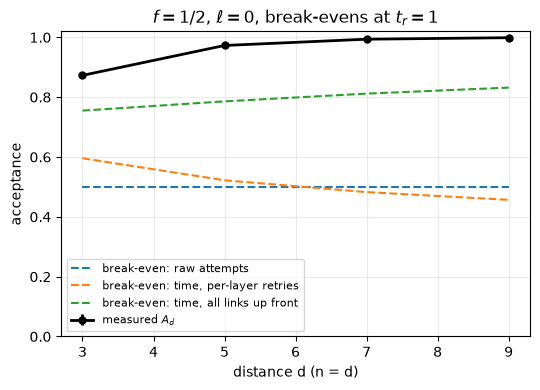

In [17]:
ds = sorted(acc)
A = np.array([acc[d][0] for d in ds])
print(f"{'d':>3} {'A_d':>7}  " + "  ".join(f"{'G ' + m + ', t_r=' + str(t):>24}"
                                          for m in ("attempts", "time") for t in ((0.0,) if m == "attempts" else (0.0, 1.0, 10.0))))
for d, a in zip(ds, A):
    g = [a / s] + [time_A(d, d, s, t) / time_B(d, d, a, t) for t in (0.0, 1.0, 10.0)]
    print(f"{d:>3} {a:>7.4f}  " + "  ".join(f"{x:>24.3f}" for x in g))

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.errorbar(ds, A, yerr=[stderr(a, SHOTS) for a in A], fmt="ko-", ms=5, lw=2, label="measured $A_d$")
for model, label in models.items():
    ax.plot(ds, [breakeven_A(d, d, s, 1.0, model) for d in ds], "--", lw=1.5, label=f"break-even: {label}")
ax.set(xlabel="distance d (n = d)", ylabel="acceptance", ylim=(0, 1.02),
       title="$f=1/2$, $\\ell=0$, break-evens at $t_r=1$")
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
fig.tight_layout()

## 11. Loss: the advantage region in $\ell$

Sweep $\ell$ at $f=1/2$. Strategy B has the resource advantage where $A_d(\ell) > s(\ell) = (1-\ell)/2$. Large-$d$ intuition: each sector percolates at $q = 1/2$, i.e. $\ell = 1/3$.

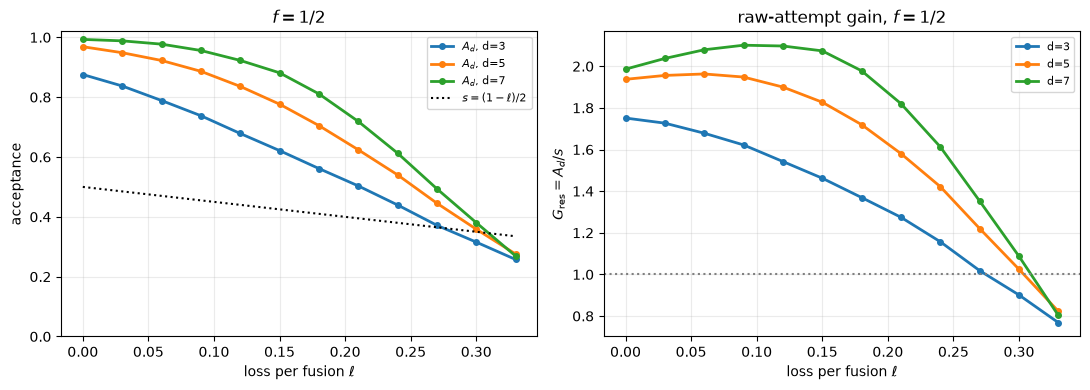

In [18]:
losses = np.round(np.arange(0, 0.36, 0.03), 3)
SWEEP_SHOTS = 5_000
sweep = {d: [sample_acceptance(d, d, 0.5, l, SWEEP_SHOTS, seed=100 + d)[0] for l in losses]
         for d in (3, 5, 7)}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for d, a in sweep.items():
    axes[0].plot(losses, a, "o-", ms=4, lw=2, label=f"$A_d$, d={d}")
    axes[1].plot(losses, np.array(a) / ((1 - losses) / 2), "o-", ms=4, lw=2, label=f"d={d}")
axes[0].plot(losses, (1 - losses) / 2, "k:", lw=1.5, label="$s = (1-\\ell)/2$")
axes[0].set(xlabel="loss per fusion $\\ell$", ylabel="acceptance", ylim=(0, 1.02), title="$f=1/2$")
axes[1].axhline(1, color="0.5", ls=":", lw=1.5)
axes[1].set(xlabel="loss per fusion $\\ell$", ylabel="$G_\\mathrm{res} = A_d / s$",
            title="raw-attempt gain, $f = 1/2$")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()

In [19]:
for d, a in sweep.items():
    g = np.array(a) / ((1 - losses) / 2)
    i = np.argmax(g < 1) if (g < 1).any() else None
    print(f"d={d}: G_res > 1 up to ℓ ≈ {losses[i - 1] if i else losses[-1]}"
          + (f" (crosses 1 before {losses[i]})" if i else " (whole sweep)"))

d=3: G_res > 1 up to ℓ ≈ 0.27 (crosses 1 before 0.3)
d=5: G_res > 1 up to ℓ ≈ 0.3 (crosses 1 before 0.33)
d=7: G_res > 1 up to ℓ ≈ 0.3 (crosses 1 before 0.33)


# Part III: adaptive failure basis

## 12. Choosing which outcome a failure keeps

A failed fusion measures one of its two parities, and which one is set by the fusion's configuration before it fires. Following Bombin et al., that choice can be made adaptively from the heralds already received, steering erasures away from configurations that would make a logical label ambiguous.

**Greedy rule.** Process fusions in time order and keep the erased graph of each build as a parity union-find. Before a fusion fires, test both failure bases: would erasing its $XX$ outcome (or its $ZZ$ outcome) close an erased cycle of odd observable parity in either build? If exactly one is harmful, set the fusion so that a failure erases the other. Otherwise choose at random, as in the baseline. On success the choice is irrelevant, and loss erases both regardless. This is a one-step lookahead: it only avoids the failure that would *immediately* cause ambiguity.

**Causality.** All fusions in a merge layer fire together, so the choice for a layer can only use heralds from earlier layers (`"layer"`). The `"sequential"` policy lets each fusion also see earlier fusions in its own layer. That needs a layer's links to be generated one after another and held until the layer's local gates, rather than all fired together. It costs time in strategy B's schedule, but it is not unphysical.

In [20]:
class ParityUnionFind:
    # Erased-edge graph; each node stores its parity relative to its root.
    def __init__(self):
        self.parent, self.parity = {}, {}

    def find(self, x):
        path, p = [], 0
        while self.parent.get(x, x) != x:
            path.append(x)
            p ^= self.parity[x]
            x = self.parent[x]
        acc = p
        for y in path:  # path compression, keeping parities relative to the root
            acc, self.parity[y] = acc ^ self.parity[y], acc
            self.parent[y] = x
        return x, p

    def closes_odd(self, u, v, o) -> bool:
        (ru, pu), (rv, pv) = self.find(u), self.find(v)
        return ru == rv and bool(pu ^ pv ^ o)

    def add(self, u, v, o) -> bool:
        # Add an erased edge; True if it closes an odd cycle (ambiguity).
        (ru, pu), (rv, pv) = self.find(u), self.find(v)
        if ru == rv:
            return bool(pu ^ pv ^ o)
        self.parent[ru], self.parity[ru] = rv, pu ^ pv ^ o
        return False


def sample_adaptive(d: int, n: int, f: float, loss: float, shots: int,
                    policy: str = "layer", seed: int = 0):
    # Accepted fraction, and switches per shot, under failure-basis `policy`:
    # "random", "layer" (causal, per merge layer) or "sequential" (idealised).
    fus = interface(d, n, "ZZ")
    E = [edges(fus), edges(interface(d, n, "XX"))]
    N = len(fus)
    times = [f_[0] for f_ in fus]
    layers = ([[i for i in range(N) if times[i] == t] for t in sorted(set(times))]
              if policy == "layer" else [[i] for i in range(N)])
    rng = np.random.default_rng(seed)
    u = rng.random((shots, N))
    lost, failed = u < loss, (u >= loss) & (u < loss + (1 - loss) * f)
    default = rng.random((shots, N)) < 0.5  # slot a failure erases: 0 XX, 1 ZZ

    accepted = switches = 0
    for shot in range(shots):
        ufs = [ParityUnionFind(), ParityUnionFind()]
        ok = True
        for layer in layers:
            erase = []
            for i in layer:
                if lost[shot, i]:
                    erase += [(i, 0), (i, 1)]
                elif failed[shot, i]:
                    slot = int(default[shot, i])
                    if policy != "random":
                        harm = [any(uf.closes_odd(*E[b][i][s]) for b, uf in enumerate(ufs)) for s in (0, 1)]
                        if harm[slot] and not harm[1 - slot]:
                            slot, switches = 1 - slot, switches + 1
                    erase.append((i, slot))
            if any(uf.add(*E[b][i][s]) for i, s in erase for b, uf in enumerate(ufs)):
                ok = False
                break
        accepted += ok
    return accepted / shots, switches / shots

Checks: the path-compressed union-find must agree with the rank test edge by edge, and the `"random"` policy is the §10 sampler written incrementally, so it must reproduce the $A_d$ measured there.

In [21]:
rng = np.random.default_rng(2)
for d in (3, 5):
    for b, obs in enumerate(("ZZ", "XX")):
        fus, Eb = interface(d, d, obs), edges(interface(d, d, obs))
        for _ in range(300):
            picks = [(i, slot) for i in rng.permutation(len(fus)) for slot in (0, 1) if rng.random() < 0.3]
            uf, amb = ParityUnionFind(), False
            for j, (i, slot) in enumerate(picks):
                amb |= uf.add(*Eb[i][slot])
                if j % 5 == 0:  # also check prefixes
                    assert amb == (k_rank([fus[i][3][slot] for i, slot in picks[:j + 1]]) == 1)
            assert amb == (k_rank([fus[i][3][slot] for i, slot in picks]) == 1)

for d in (3, 5):
    a, _ = sample_adaptive(d, d, 0.5, 0.0, SHOTS, "random", seed=7)
    print(f"d={d}: incremental {a:.4f}, §10 {acc[d][0]:.4f}, diff {abs(a - acc[d][0]) / stderr(a, SHOTS):.1f} σ")
    assert abs(a - acc[d][0]) < 4 * np.sqrt(2) * stderr(a, SHOTS)

d=3: incremental 0.8772, §10 0.8728, diff 1.9 σ


d=5: incremental 0.9722, §10 0.9728, diff 0.5 σ


## 13. Fusion failure only ($f = 1/2$, $\ell = 0$)

In [22]:
policies = {"random": "random basis", "layer": "adaptive, per layer",
            "sequential": "adaptive, sequential"}
adaptive = {}
for d in (3, 5, 7, 9):
    for pol in policies:
        adaptive[d, pol] = sample_adaptive(d, d, 0.5, 0.0, SHOTS, pol, seed=d)
    print(f"d={d}: " + "   ".join(f"{pol} A={adaptive[d, pol][0]:.4f} (switches/shot {adaptive[d, pol][1]:.2f})"
                                     for pol in policies))

d=3: random A=0.8742 (switches/shot 0.00)   layer A=0.9186 (switches/shot 0.05)   sequential A=0.9954 (switches/shot 0.14)


d=5: random A=0.9726 (switches/shot 0.00)   layer A=0.9833 (switches/shot 0.01)   sequential A=0.9999 (switches/shot 0.03)


d=7: random A=0.9947 (switches/shot 0.00)   layer A=0.9964 (switches/shot 0.00)   sequential A=1.0000 (switches/shot 0.01)


d=9: random A=0.9990 (switches/shot 0.00)   layer A=0.9994 (switches/shot 0.00)   sequential A=1.0000 (switches/shot 0.00)


Rejections $1-A_d$ on a log scale, which is where the policies differ. The ratio to the random baseline shows how much of the rejection the lookahead removes. A policy with no rejections in `SHOTS` shots is drawn as a ▼ at the 95% upper limit $3/\text{SHOTS}$.

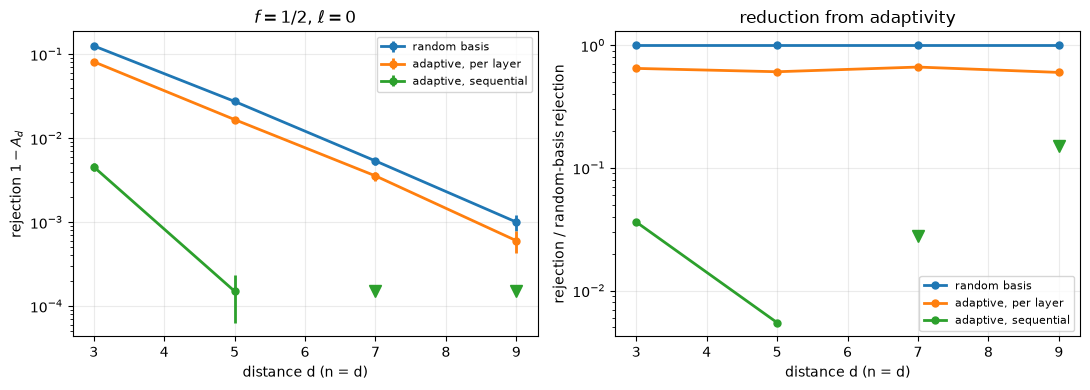

In [23]:
ds = [3, 5, 7, 9]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
base = np.array([1 - adaptive[d, "random"][0] for d in ds])
for k, (pol, label) in enumerate(policies.items()):
    rej = np.array([1 - adaptive[d, pol][0] for d in ds])
    seen = rej > 0
    err = [stderr(adaptive[d, pol][0], SHOTS) for d in ds]
    axes[0].errorbar(np.array(ds)[seen], rej[seen], yerr=np.array(err)[seen], fmt="o-",
                     color=f"C{k}", ms=5, lw=2, label=label)
    axes[1].plot(np.array(ds)[seen], (rej / base)[seen], "o-", color=f"C{k}", ms=5, lw=2, label=label)
    if (~seen).any():
        axes[0].plot(np.array(ds)[~seen], np.full((~seen).sum(), 3 / SHOTS), "v", color=f"C{k}", ms=8)
        axes[1].plot(np.array(ds)[~seen], 3 / SHOTS / base[~seen], "v", color=f"C{k}", ms=8)
axes[0].set(xlabel="distance d (n = d)", ylabel="rejection $1 - A_d$", yscale="log",
            title="$f=1/2$, $\\ell=0$")
axes[1].set(xlabel="distance d (n = d)", ylabel="rejection / random-basis rejection",
            yscale="log", title="reduction from adaptivity")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()

The per-layer rule helps only modestly, removing about 40% of rejections at every $d$, while sequential removes almost all of them. So most fatal closures are completed by a fusion *in the same layer* as the rest of the closing set: the layer's $d$ or $d-1$ fusions sit side by side along the seam, and the ambiguity forms within one round, invisible to a choice made from earlier layers only.

## 14. Exposure-based adaptivity (Bombín, Dawson, Nickerson, Pant, Sullivan, arXiv:2303.16122)

**XBA as published.** Each fusion contributes one edge to the primal and one to the dual syndrome graph, and the failure basis decides which of the two a failure erases. A *cluster* is a set of checks connected by erased edges.

* **Trivial rule.** An edge whose ends are already in the same cluster is *intra-cluster*. Its outcome cannot connect anything new, so a failure should erase that edge.
* **Exposure.** A cluster's exposure is the sum over the edges incident to its checks: 1 for each unmeasured edge and $a$ ("accretion", $a=0.5$ in the paper) for each measured one. It measures the cluster's room to grow. An unmeasured edge's exposure $\chi$ is the product of the exposures of the clusters at its two ends, excluding the edge itself, an idea taken from explosive percolation.
* **Choice.** A bias in $[0,1]$ is computed from $\chi_1, \chi_2$ (exposure exponent $\xi$, squeeze $s$), and the fusion option minimising $(1-\text{bias})\Pr[E_1\text{ erased}] + \text{bias}\Pr[E_2\text{ erased}]$ is chosen. Fusions are performed fully sequentially (interleaving).

**Reduction to our case.** With unboosted fusion the only options are XX-fail and ZZ-fail. The cost then just compares bias with 1/2, so the rule is *erase the edge with the lower exposure*. $\xi$ and $s$ only matter when boosting gives extra options.

**One necessary change: boundaries.** The paper's lattices are periodic, so an intra-cluster edge is almost always useless (their footnote 2 is the exception). Our sectors have boundaries, merged into one boundary node, and an intra-cluster edge is then one of two kinds. If the existing path between its ends has the same observable parity as the edge, it is *useless*, so erase it. If the parity differs, it is *fatal*: erasing it makes the label ambiguous, so protect it. The greedy rule of §12 is the fatal case alone. XBA adds the useless rule and the exposure ranking. A cluster attached to the boundary node also inherits the boundary's incident edges, so edges near a boundary-attached cluster rank as highly exposed, as they should.

### The two sector graphs

Check that the $\bar Z\bar Z$ sector (primal) and the $\bar X\bar X$ sector (dual) each use exactly one outcome of every fusion. Each is one component over the detectors, and only it contains observable-flipping edges.

In [24]:
def sector_slots(fus):
    # Per fusion, which outcome slots lie in the component(s) holding the observable.
    uf = ParityUnionFind()
    for e in edges(fus):
        for u, v, _ in e:
            if BOUNDARY not in (u, v):
                uf.add(u, v, 0)
    root = lambda x: uf.find(x)[0]
    relevant = {root(u) for e in edges(fus) for u, v, o in e if o}
    return [[root(u) in relevant for u, v, _ in e] for e in edges(fus)], len(relevant)


for d in (3, 5, 7):
    (sz, kz), (sx, kx) = sector_slots(interface(d, d, "ZZ")), sector_slots(interface(d, d, "XX"))
    assert kz == kx == 1
    assert all(r == [False, True] for r in sz) and all(r == [True, False] for r in sx)
print("ZZ-observable sector = every ZZ outcome; XX-observable sector = every XX outcome")


def sectors(d: int, n: int):
    # (primal, dual) edge lists, one edge per fusion: ZZ outcomes in the ZZ build,
    # XX outcomes in the XX build. Index 0/1 also equals the outcome slot a failure erases + 1.
    return ([e[1] for e in edges(interface(d, n, "ZZ"))],
            [e[0] for e in edges(interface(d, n, "XX"))])

ZZ-observable sector = every ZZ outcome; XX-observable sector = every XX outcome


### Implementation

Each sector is a parity union-find that also keeps every cluster's exposure at its root. Measuring an edge changes its weight at each end from 1 to $a$, and erasing it removes it (weight 0) and merges the two clusters. Exposures are counted per endpoint, so an edge with both ends in one cluster counts twice. That only affects intra-cluster edges, which the trivial rules handle anyway.

`importance(i)` ranks a fusion's edge in a sector: $+\infty$ if erasing it is fatal, $-\infty$ if it is useless, otherwise $\chi$. A failure erases the less important of the two edges, with ties broken at random as in the baseline. The `greedy` policy only uses the fatal rule, so it is §12's rule in this framework and must reproduce §13.

In [25]:
class Sector(ParityUnionFind):
    # One logical sector: erased-edge clusters with parities and exposures.
    def __init__(self, edge_list, accretion: float):
        super().__init__()
        self.edges, self.a = edge_list, accretion
        self.expo = collections.Counter()
        for u, v, _ in edge_list:  # every edge starts unmeasured: weight 1 at each end
            self.expo[u] += 1
            self.expo[v] += 1

    def importance(self, i: int, exposure: bool = True) -> float:
        u, v, o = self.edges[i]
        (ru, pu), (rv, pv) = self.find(u), self.find(v)
        if ru == rv:
            return np.inf if pu ^ pv ^ o else -np.inf
        return (self.expo[ru] - 1) * (self.expo[rv] - 1) if exposure else 0.0

    def measure(self, i: int):
        for x in self.edges[i][:2]:
            self.expo[self.find(x)[0]] += self.a - 1

    def erase(self, i: int) -> bool:
        # Erase edge i; True if that makes the label ambiguous.
        u, v, o = self.edges[i]
        ru, rv = self.find(u)[0], self.find(v)[0]
        self.expo[ru] -= 1
        self.expo[rv] -= 1
        if self.add(u, v, o):
            return True
        if ru != rv:
            new = self.find(u)[0]
            old = rv if new == ru else ru
            self.expo[new] += self.expo.pop(old)
        return False


def sample_policy(d: int, n: int, f: float, loss: float, shots: int, policy: str = "xba",
                  schedule: str = "sequential", accretion: float = 0.5, seed: int = 0,
                  patterns: list | None = None) -> float:
    # Accepted fraction. policy: "random", "static" (failures on ZZ-type layers erase
    # the ZZ outcome, on XX-type layers the XX outcome), "greedy" (fatal rule only) or "xba";
    # schedule: "sequential" or "layer" (choices see only earlier layers).
    # If `patterns` is a list, each accepted shot's erased (fusion, slot) pairs are appended.
    primal, dual = sectors(d, n)
    N = len(primal)
    times = [f_[0] for f_ in interface(d, n, "ZZ")]
    groups = ([[i for i in range(N) if times[i] == t] for t in sorted(set(times))]
              if schedule == "layer" else [[i] for i in range(N)])
    zz_layer = [sorted(set(times)).index(t) % 2 == 0 for t in times]
    rng = np.random.default_rng(seed)
    u = rng.random((shots, N))
    lost, failed = u < loss, (u >= loss) & (u < loss + (1 - loss) * f)
    default = rng.random((shots, N)) < 0.5  # True: a failure erases the primal (ZZ) edge

    accepted = 0
    for shot in range(shots):
        sec = (Sector(primal, accretion), Sector(dual, accretion))
        ok, erased = True, []
        for group in groups:
            erase_primal = {}
            for i in group:  # decide every failure basis in the group first
                if policy == "random":
                    erase_primal[i] = default[shot, i]
                elif policy == "static":
                    erase_primal[i] = zz_layer[i]
                else:
                    ip, id_ = (s.importance(i, exposure=policy == "xba") for s in sec)
                    erase_primal[i] = default[shot, i] if ip == id_ else ip < id_
            for i in group:
                if lost[shot, i]:
                    gone = (True, True)
                elif failed[shot, i]:
                    gone = (erase_primal[i], not erase_primal[i])
                else:
                    gone = (False, False)
                for slot, s, g in zip((1, 0), sec, gone):  # primal = ZZ slot, dual = XX slot
                    if not g:
                        s.measure(i)
                        continue
                    erased.append((i, slot))
                    if s.erase(i):
                        ok = False
                if not ok:
                    break
            if not ok:
                break
        accepted += ok
        if ok and patterns is not None:
            patterns.append(erased)
    return accepted / shots

Consistency: `random` and `greedy` in this two-sector framework must reproduce §13, which used the full graphs of both builds.

In [26]:
for d in (3, 5):
    for pol, sched, old in (("random", "sequential", "random"), ("greedy", "layer", "layer"),
                            ("greedy", "sequential", "sequential")):
        a = sample_policy(d, d, 0.5, 0.0, SHOTS, pol, sched, seed=11)
        ref = adaptive[d, old][0]
        z = abs(a - ref) / (np.sqrt(2) * stderr(max(a, ref) if max(a, ref) < 1 else 1 - 1 / SHOTS, SHOTS))
        print(f"d={d} {pol:>6}/{sched:<10}: {a:.4f} vs §13 {ref:.4f} ({z:.1f} σ)")
        assert z < 4

d=3 random/sequential: 0.8745 vs §13 0.8742 (0.1 σ)


d=3 greedy/layer     : 0.9203 vs §13 0.9186 (0.6 σ)


d=3 greedy/sequential: 0.9961 vs §13 0.9954 (1.1 σ)


d=5 random/sequential: 0.9728 vs §13 0.9726 (0.1 σ)


d=5 greedy/layer     : 0.9839 vs §13 0.9833 (0.4 σ)


d=5 greedy/sequential: 0.9999 vs §13 0.9999 (0.0 σ)


### Fusion failure only ($f=1/2$, $\ell=0$)

In [27]:
XBA_SHOTS = 50_000
variants = {("random", None): "random basis", ("static", None): "static (by layer type)",
            ("greedy", None): "greedy (fatal rule)",
            ("xba", 0.0): "XBA, $a=0$", ("xba", 0.5): "XBA, $a=0.5$"}
xba = {}
for sched in ("layer", "sequential"):
    for d in (3, 5):
        for (pol, acc_), label in variants.items():
            xba[sched, d, pol, acc_] = sample_policy(d, d, 0.5, 0.0, XBA_SHOTS, pol, sched,
                                                     accretion=acc_ or 0.0, seed=20 + d)
print(f"{'rejection 1 - A_d':<24}" + "".join(f"{s + ' d=' + str(d):>17}" for s in ("layer", "sequential") for d in (3, 5)))
for k, label in variants.items():
    print(f"{label.replace('$', ''):<24}" + "".join(f"{1 - xba[s, d, *k]:>17.2e}" for s in ("layer", "sequential") for d in (3, 5)))
print(f"(0 means no rejections in {XBA_SHOTS} shots: below {3 / XBA_SHOTS:.0e} at 95%)")

rejection 1 - A_d               layer d=3        layer d=5   sequential d=3   sequential d=5
random basis                     1.25e-01         2.82e-02         1.25e-01         2.82e-02
static (by layer type)           1.75e-01         7.50e-02         1.75e-01         7.50e-02
greedy (fatal rule)              8.12e-02         1.72e-02         4.30e-03         1.20e-04
XBA, a=0                         8.00e-04         0.00e+00         2.00e-05         0.00e+00
XBA, a=0.5                       2.79e-02         6.96e-03         1.56e-03         0.00e+00
(0 means no rejections in 50000 shots: below 6e-05 at 95%)


### With loss

Loss erases both outcomes whatever the basis, and the paper's gains are largest in this loss-dominated regime. Rejection $1-A_d$ vs $\ell$ at $f=1/2$, $d=5$, for both schedules (▼: no rejections in `LOSS_SHOTS`, drawn at the 95% upper limit).

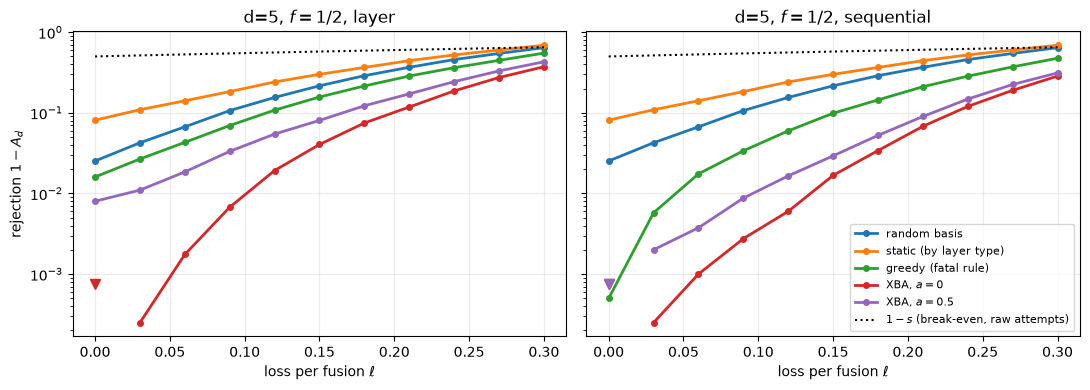

In [28]:
losses_x = np.round(np.arange(0, 0.31, 0.03), 3)
LOSS_SHOTS = 4_000
xba_loss = {(sched, k): [sample_policy(5, 5, 0.5, l, LOSS_SHOTS, k[0], sched, accretion=k[1] or 0.0, seed=300)
                         for l in losses_x]
            for sched in ("layer", "sequential") for k in variants}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, sched in zip(axes, ("layer", "sequential")):
    for c, (k, label) in enumerate(variants.items()):
        rej = 1 - np.array(xba_loss[sched, k])
        seen = rej > 0
        ax.plot(losses_x[seen], rej[seen], "o-", color=f"C{c}", ms=4, lw=2, label=label)
        ax.plot(losses_x[~seen], np.full((~seen).sum(), 3 / LOSS_SHOTS), "v", color=f"C{c}", ms=7)
    ax.plot(losses_x, 1 - (1 - losses_x) / 2, "k:", lw=1.5, label="$1 - s$ (break-even, raw attempts)")
    ax.set(xlabel="loss per fusion $\\ell$", yscale="log", title=f"d=5, $f=1/2$, {sched}")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("rejection $1 - A_d$")
axes[1].legend(fontsize=8)
fig.tight_layout()

In [29]:
for sched in ("layer", "sequential"):
    print(sched)
    for k, label in variants.items():
        g = np.array(xba_loss[sched, k]) / ((1 - losses_x) / 2)
        cross = losses_x[np.argmax(g < 1)] if (g < 1).any() else None
        print(f"  {label.replace('$', ''):<24} G_res at ℓ=0.15: {g[list(losses_x).index(0.15)]:.2f}   "
              f"G_res < 1 from ℓ ≈ {cross}")

layer
  random basis             G_res at ℓ=0.15: 1.84   G_res < 1 from ℓ ≈ None
  static (by layer type)   G_res at ℓ=0.15: 1.65   G_res < 1 from ℓ ≈ 0.3
  greedy (fatal rule)      G_res at ℓ=0.15: 1.98   G_res < 1 from ℓ ≈ None
  XBA, a=0                 G_res at ℓ=0.15: 2.26   G_res < 1 from ℓ ≈ None
  XBA, a=0.5               G_res at ℓ=0.15: 2.16   G_res < 1 from ℓ ≈ None
sequential
  random basis             G_res at ℓ=0.15: 1.84   G_res < 1 from ℓ ≈ None
  static (by layer type)   G_res at ℓ=0.15: 1.65   G_res < 1 from ℓ ≈ 0.3
  greedy (fatal rule)      G_res at ℓ=0.15: 2.12   G_res < 1 from ℓ ≈ None
  XBA, a=0                 G_res at ℓ=0.15: 2.31   G_res < 1 from ℓ ≈ None
  XBA, a=0.5               G_res at ℓ=0.15: 2.28   G_res < 1 from ℓ ≈ None


### What XBA does here

* **Per-layer XBA beats every other policy, including sequential greedy.** With only heralds from earlier layers it reaches $1-A_3 \approx 8\times10^{-4}$, against $4\times10^{-3}$ for sequential greedy and $8\times10^{-2}$ for per-layer greedy. Ranking edges by their clusters' room to grow anticipates ambiguities that the one-step fatal rule only sees once they are one edge from closing, and that is exactly the information a per-layer choice is missing.
* **$a = 0$ beats the paper's $a=0.5$.** With erasure only, a measured edge can never join a cluster, so counting it only blurs the ranking. The paper sets $a>0$ for Pauli noise.
* **The gain is dynamic.** XBA's choices follow a strong pattern (failures on ZZ-type layers mostly erase the ZZ outcome, on XX-type layers the XX outcome), but the static policy with that pattern is *worse* than random ($1-A_3 = 0.175$ vs $0.125$). The gain comes entirely from the departures from the pattern.
* **With loss** the ordering is unchanged. From worst to best: static, random, greedy, XBA ($a=0.5$), XBA ($a=0$). The gap closes as loss, which no basis choice can steer, takes over near $\ell \approx 0.3$.

# Part IV: logical rate at fixed fidelity, with memory decoherence

With fusion failure as the only noise both strategies have fidelity 1 at every $d$. The real cost of physical post-selection is *waiting*: while A retries, the data and the Bell pairs it has already made sit in memory and decohere. A therefore needs a larger $d$ for the same fidelity, which costs rate on top of the waiting itself. B waits one attempt slot per layer but restarts on rejection.

## 15. Assumptions

| | |
|---|---|
| fusion | $f = 1/2$, $\ell = 0$ (so $s = 1/2$), attempt time $\tau = 1/r$ per link, every link with its own source |
| local layer | $t_r = 1\,\mu$s, local gates otherwise ideal; $n = d$ |
| memory | every qubit idles under depolarising noise $p(\Delta t) = \tfrac34\,(1-e^{-\Delta t/T_\text{mem}})$, $T_\text{mem} = 1$ ms |
| noise placement | $p(t_r)$ on every qubit at the start of every layer; in each merge layer an extra $p(W)$ on every qubit just before the fusions, i.e. on the data and the stored Bell-pair halves while links are made |
| wait $W$ | A: slowest link of the layer, $\mathbb E[M_{m_t}]\,\tau$ (§3, mean wait); B: one slot, $\tau$ |
| B | XBA with $a=0$, per-layer (causal) schedule; accept iff no erasure ambiguity; decode with the erased edges at weight 0 |
| A | only complete Bell pairs, so no erasures; plain MWPM |
| fidelity | $1-F = 1-(1-P_{\bar Z\bar Z})(1-P_{\bar X\bar X})$ from the two builds (independent-sector approximation); target $1-F \le 10^{-3}$ |
| rate | $R_A = 1/T_A$, $R_B = A_d/T_B$ (§3, per-layer retries), at the smallest $d \in \{3,5,7\}$ meeting the target |

Using the mean wait for A understates its errors, because the logical error rate is convex in $p$. That approximation favours A.

In [30]:
import multiprocessing

import pymatching
import stim

T_R, T_MEM, TARGET = 1e-6, 1e-3, 1e-3
DS = (3, 5, 7)
assert s == fusion_channel(0.5, 0.0)["s"]  # the §4 global, used by waits() and rate()


def p_mem(dt: float) -> float:
    return 0.75 * (1 - np.exp(-dt / T_MEM))


@functools.cache
def clean_circuit(d: int, observable: str) -> stim.Circuit:
    return build_surgery_bell_prep_fusion_zigzag(d, d, observable=observable).circuit


def merge_times(d: int) -> list:
    return sorted({f_[0] for f_ in interface(d, d, "ZZ")})


def with_memory_noise(circuit: stim.Circuit, waits: dict) -> stim.Circuit:
    # p(t_r) on every qubit at each layer start, plus p(waits[t]) before layer t's fusions.
    out, qubits, last_t, waited = stim.Circuit(), range(circuit.num_qubits), None, set()
    for inst in circuit.flattened():
        tag = json.loads(inst.tag) if inst.tag else {}
        t = tag.get("t")
        if t is not None and t != last_t:
            out.append("DEPOLARIZE1", qubits, p_mem(T_R))
            last_t = t
        if tag.get("operation") == "fusion_gate" and t not in waited and waits.get(t, 0) > 0:
            out.append("DEPOLARIZE1", qubits, p_mem(waits[t]))
            waited.add(t)
        out.append(inst)
    return out


def waits(d: int, r: float, strategy: str) -> dict:
    tau = 1 / r
    return {t: (expected_max_geometric(k, s) if strategy == "A" else 1) * tau
            for t, k in zip(merge_times(d), layer_sizes(d, d))}


noisy = with_memory_noise(clean_circuit(3, "ZZ"), waits(3, 1e6, "A"))
assert noisy.without_noise() == clean_circuit(3, "ZZ").flattened().without_noise()
print(sum(i.name == "DEPOLARIZE1" for i in noisy), "DEPOLARIZE1 instructions at d=3:",
      6 * 3, "layers +", len(merge_times(3)), "merge waits")

25 DEPOLARIZE1 instructions at d=3: 18 layers + 7 merge waits


### Decoding with per-shot erasures

The noise insertion leaves the detectors unchanged, so the fusion-outcome columns of §8 still apply. For B, each accepted shot's erased outcomes get a uniformly random flip XORed into their detectors and observable, and the matching graph gets those edges at weight 0 through `decode_batch(edge_reweights=...)` (the reweighting PyMatching build). Every outcome column must be an edge of the matching graph with the same observable. A missing column is added at negligible weight so that it can be reweighted.

In [31]:
def matching_for(noisy: stim.Circuit, fus) -> pymatching.Matching:
    m = pymatching.Matching.from_detector_error_model(noisy.detector_error_model(decompose_errors=True))
    for *_, cols in fus:
        for dets, o in cols:
            u, v = (*sorted(dets), -1)[:2]
            fault = {0} if o else set()
            if v == -1:
                if m.has_boundary_edge(u):
                    assert set(m.get_boundary_edge_data(u)["fault_ids"]) == fault
                else:
                    m.add_boundary_edge(u, fault_ids=fault, weight=30.0)
            elif m.has_edge(u, v):
                assert set(m.get_edge_data(u, v)["fault_ids"]) == fault
            else:
                m.add_edge(u, v, fault_ids=fault, weight=30.0)
    return m


def logical_error(d: int, observable: str, wait: dict, patterns=None, shots: int = 0, seed: int = 0) -> float:
    # Logical error rate of one label. patterns: erased (fusion, slot) lists, one per shot (B);
    # None for no erasures (A), with `shots` shots.
    fus = interface(d, d, observable)
    noisy = with_memory_noise(clean_circuit(d, observable), wait)
    m = matching_for(noisy, fus)
    n_shots = len(patterns) if patterns is not None else shots
    dets, obs = noisy.compile_detector_sampler(seed=seed).sample(n_shots, separate_observables=True)
    if patterns is None:
        pred = m.decode_batch(dets)
    else:
        rng, rows = np.random.default_rng(seed + 1), []
        for k, erased in enumerate(patterns):
            rw = []
            for i, slot in erased:
                dset, o = fus[i][3][slot]
                u, v = (*sorted(dset), -1)[:2]
                rw.append((u, v, 0.0))
                if rng.random() < 0.5:  # erased outcome: uniformly random
                    dets[k, list(dset)] ^= True
                    obs[k, 0] ^= bool(o)
            rows.append(np.array(rw, np.float64).reshape(-1, 3))
        pred = m.decode_batch(dets, edge_reweights=rows)
    return float(np.mean(pred[:, 0] != obs[:, 0]))


WORKERS = 8


def _logical_error_job(job):
    # One (T_mem, d, observable, wait strategy, r, patterns name, seed) point, in a forked worker.
    global T_MEM
    T_MEM, d, observable, strategy, r, pats, seed = job
    return logical_error(d, observable, waits(d, r, strategy),
                         patterns=globals()[pats][d] if pats else None, shots=RATE_SHOTS, seed=seed)


def logical_errors(jobs) -> list:
    # Fork after the pattern dicts exist, so workers inherit them without pickling.
    with multiprocessing.get_context("fork").Pool(WORKERS) as pool:
        return pool.map(_logical_error_job, jobs, chunksize=1)

Sanity checks:

* With no memory noise, B's accepted shots must decode perfectly (fidelity 1 on acceptance, §9), which checks the reweighting and the flip bookkeeping end to end.
* Waits make A strictly worse.

In [32]:
T_MEM_SAVED, T_MEM = T_MEM, 1e30  # effectively no memory noise
pats = []
sample_policy(3, 3, 0.5, 0.0, 2_000, "xba", "layer", accretion=0.0, seed=1, patterns=pats)
for obs in ("ZZ", "XX"):
    assert logical_error(3, obs, {}, patterns=pats, seed=2) == 0.0
T_MEM = T_MEM_SAVED
print("noiseless memory: all accepted shots decode correctly")
lo, hi = (logical_error(3, "ZZ", waits(3, r, "A"), shots=20_000, seed=3) for r in (1e8, 1e5))
print(f"A, d=3, ZZ label: r=1e8 → {lo:.2e}, r=1e5 → {hi:.2e}")
assert hi > lo

noiseless memory: all accepted shots decode correctly


A, d=3, ZZ label: r=1e8 → 1.00e-04, r=1e5 → 9.81e-02


## 16. Sweep the physical attempt rate

B's erasure patterns depend only on the fusion heralds, not on $r$, so they are sampled once per $d$ and reused at every $r$. The memory noise is resampled for each point.

In [33]:
RATE_SHOTS = 40_000
rs = np.logspace(5, 8, 7)  # attempts per second per link

xba_patterns, A_xba = {}, {}
for d in DS:
    xba_patterns[d] = []
    A_xba[d] = sample_policy(d, d, 0.5, 0.0, RATE_SHOTS, "xba", "layer", accretion=0.0,
                             seed=500 + d, patterns=xba_patterns[d])
    print(f"d={d}: A_d (XBA, a=0, per layer) = {A_xba[d]:.5f}")

keys = [(strategy, d, r) for d in DS for strategy in ("A", "B") for r in rs]
P = logical_errors([(T_MEM, d, obs, strategy, r, "xba_patterns" if strategy == "B" else None,
                     1000 * d + 10 * list(rs).index(r) + k)
                    for strategy, d, r in keys for k, obs in enumerate(("ZZ", "XX"))])
infid = {key: 1 - (1 - P[2 * i]) * (1 - P[2 * i + 1]) for i, key in enumerate(keys)}

d=3: A_d (XBA, a=0, per layer) = 0.99900


d=5: A_d (XBA, a=0, per layer) = 1.00000


d=7: A_d (XBA, a=0, per layer) = 1.00000


In [34]:
def rate(strategy: str, d: int, r: float) -> float:
    tau = 1 / r
    T_A = 6 * d * T_R + sum(expected_max_geometric(k, s) for k in layer_sizes(d, d)) * tau
    T_B = ((4 * d + 1) * T_R + (2 * d + 1) * tau) / A_xba[d] + (2 * d - 1) * T_R
    return 1 / (T_A if strategy == "A" else T_B)


best = {}
for strategy in ("A", "B"):
    for r in rs:
        ok = [d for d in DS if infid[strategy, d, r] <= TARGET]
        best[strategy, r] = (min(ok), rate(strategy, min(ok), r)) if ok else (None, np.nan)

print(f"{'r (Hz)':>9}  {'A: d, rate (1/s)':>20}  {'B: d, rate (1/s)':>20}  {'B / A':>6}")
for r in rs:
    (da, ra), (db, rb) = best["A", r], best["B", r]
    print(f"{r:>9.1e}  {str(da):>4} {ra:>15.3e}  {str(db):>4} {rb:>15.3e}  {rb / ra if ra == ra else np.inf:>6.2f}")

   r (Hz)      A: d, rate (1/s)      B: d, rate (1/s)   B / A
  1.0e+05  None             nan  None             nan     inf
  3.2e+05  None             nan  None             nan     inf
  1.0e+06     7       9.600e+03  None             nan     nan
  3.2e+06     5       2.340e+04  None             nan     nan
  1.0e+07     3       4.986e+04     7       2.299e+04    0.46
  3.2e+07     3       5.362e+04     7       2.354e+04    0.44
  1.0e+08     3       5.493e+04     5       3.321e+04    0.60


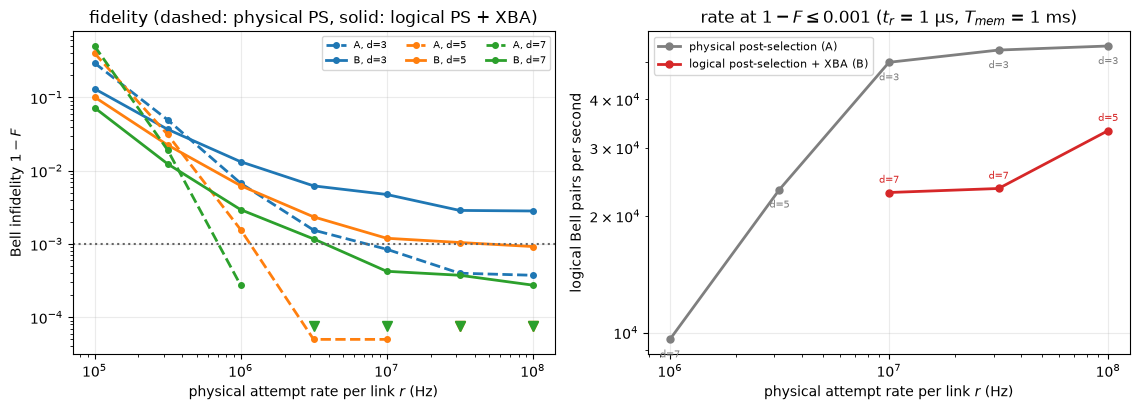

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
for c, d in enumerate(DS):
    for strategy, ls in (("A", "--"), ("B", "-")):
        y = np.array([infid[strategy, d, r] for r in rs])
        seen = y > 0
        axes[0].plot(rs[seen], y[seen], ls, marker="o", color=f"C{c}", ms=4, lw=2,
                     label=f"{'A' if strategy == 'A' else 'B'}, d={d}")
        axes[0].plot(rs[~seen], np.full((~seen).sum(), 3 / RATE_SHOTS), "v", color=f"C{c}", ms=7)
axes[0].axhline(TARGET, color="0.4", ls=":", lw=1.5)
axes[0].set(xscale="log", yscale="log", xlabel="physical attempt rate per link $r$ (Hz)",
            ylabel="Bell infidelity $1 - F$",
            title="fidelity (dashed: physical PS, solid: logical PS + XBA)")
axes[0].legend(fontsize=7, ncol=3)

for strategy, label, c in (("A", "physical post-selection (A)", "C7"), ("B", "logical post-selection + XBA (B)", "C3")):
    y = np.array([best[strategy, r][1] for r in rs])
    axes[1].plot(rs, y, "o-", color=c, ms=5, lw=2, label=label)
    for r in rs:
        d, val = best[strategy, r]
        if d:
            axes[1].annotate(f"d={d}", (r, val), textcoords="offset points",
                             xytext=(0, 7 if strategy == "B" else -13), ha="center", fontsize=7, color=c)
axes[1].set(xscale="log", yscale="log", xlabel="physical attempt rate per link $r$ (Hz)",
            ylabel="logical Bell pairs per second",
            title=f"rate at $1-F \\leq {TARGET:g}$ ($t_r$ = 1 µs, $T_{{mem}}$ = 1 ms)")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()

### What this shows

**With XBA alone, logical post-selection loses to physical post-selection.** B only meets $1-F \le 10^{-3}$ from $r = 10^7$ Hz, and then at $d=7$. A meets it from $r = 10^6$ Hz ($d=7$) and at $d=3$ from $r=10^7$ Hz. Where waiting is negligible, B needs $d=5$–$7$ to match A at $d=3$, so its rate is 0.44–0.6× A's.

The cause is what B accepts, not XBA:

* An accepted shot still has about $N/2$ erased outcomes (25 of 50 fusions at $d=5$). "No ambiguity" only excludes *fully* erased logical paths. A path with all but a few edges erased is accepted, and then one or two memory errors on its remaining edges complete a logical error. This is the order-$p$ failure mode noted in the draft's Pauli bound.
* At $d=5$, $r=10^8$, every herald-only policy gives accepted infidelity $\sim 10^{-3}$: random $2.4\times10^{-3}$, greedy $2.5\times10^{-3}$, XBA $a=0.5$ $1.1\times10^{-3}$, XBA $a=0$ $1.1\times10^{-3}$. A at the same $d$ gives about $2\times10^{-5}$. XBA is slightly better than random here, not worse.
* B's decoding path was checked: with empty erasure patterns it reproduces A's logical error rate exactly (same seed, $d=3$, $r=10^5$), and with no memory noise every accepted shot decodes correctly.

## 17. Steering failures to protect residual distance

The *residual distance* of a sector is the minimum number of **unerased** fusion outcomes on a logical path. Erased edges are free, so it is the length of the shortest boundary-to-boundary path of odd observable parity with erased edges at weight 0. Residual 0 is exactly ambiguity. XBA only avoids residual 0, so the shots it accepts are typically left at residual 1–2.

**Policy.** For each sector, keep 0-1 BFS distances $D_0, D_1$ from the boundary node at observable parity 0 and 1, with residual $R = D_0(\text{boundary}, 1)$. Erasing edge $(u, v, o)$ would leave
$$R' = \min\big(R,\ \min_{p}\, D_0(u, p) + D_1(v, p \oplus o),\ \min_p\, D_0(v, p) + D_1(u, p\oplus o)\big).$$
On failure, erase the edge that keeps $\min(R_{\bar Z\bar Z}, R_{\bar X\bar X})$ larger. Ties are broken by XBA exposure ($a=0$), then at random. The schedule is per layer (causal): choices use distances from before the layer, and the distances are recomputed after it. Residual 0 must coincide with the union-find's ambiguity flag on every shot (asserted). Residual distance here counts fusion-outcome faults only, so the circuit-level residual can be smaller.

In [36]:
INF = 10**9


class ResidualSector:
    # Shortest odd-parity boundary-to-boundary path, erased edges free, others cost 1.
    def __init__(self, edge_list):
        self.edges, self.erased = edge_list, set()
        self.adj = collections.defaultdict(list)
        for i, (u, v, o) in enumerate(edge_list):
            self.adj[u].append((v, o, i))
            self.adj[v].append((u, o, i))
        self.refresh()

    def bfs(self, parity):
        start = (BOUNDARY, parity)
        dist, dq = {start: 0}, collections.deque([start])
        while dq:
            x = dq.popleft()
            n, par = x
            for m, o, i in self.adj[n]:
                w = 0 if i in self.erased else 1
                y, nd = (m, par ^ o), dist[x] + w
                if nd < dist.get(y, INF):
                    dist[y] = nd
                    (dq.appendleft if w == 0 else dq.append)(y)
        return dist

    def refresh(self):
        self.d0, self.d1 = self.bfs(0), self.bfs(1)
        self.res = self.d0.get((BOUNDARY, 1), INF)

    def after_erasing(self, i) -> int:
        u, v, o = self.edges[i]
        best = self.res
        for a, b in ((u, v), (v, u)):
            for p in (0, 1):
                best = min(best, self.d0.get((a, p), INF) + self.d1.get((b, p ^ o), INF))
        return best


def sample_residual_policy(d, n, f, loss, shots, seed=0, patterns=None, residuals=None):
    # Per-layer failure-basis choice maximising min residual distance (XBA exposure, then
    # random, as tie-breaks). Accepted fraction; optionally collect patterns and final residuals.
    primal, dual = sectors(d, n)
    N = len(primal)
    times = [f_[0] for f_ in interface(d, n, "ZZ")]
    groups = [[i for i in range(N) if times[i] == t] for t in sorted(set(times))]
    rng = np.random.default_rng(seed)
    u = rng.random((shots, N))
    lost, failed = u < loss, (u >= loss) & (u < loss + (1 - loss) * f)
    default = rng.random((shots, N)) < 0.5
    accepted = 0
    for shot in range(shots):
        res = (ResidualSector(primal), ResidualSector(dual))
        xba_ = (Sector(primal, 0.0), Sector(dual, 0.0))
        ok, erased = True, []
        for group in groups:
            gone = {}
            for i in group:
                if lost[shot, i]:
                    gone[i] = (True, True)
                elif failed[shot, i]:
                    keep_p = min(res[0].after_erasing(i), res[1].res)  # erase primal
                    keep_d = min(res[0].res, res[1].after_erasing(i))  # erase dual
                    if keep_p != keep_d:
                        ep = keep_p > keep_d
                    else:
                        ip, id_ = (x.importance(i) for x in xba_)
                        ep = default[shot, i] if ip == id_ else ip < id_
                    gone[i] = (ep, not ep)
                else:
                    gone[i] = (False, False)
            for i in group:
                for slot, r_, x, g in zip((1, 0), res, xba_, gone[i]):
                    if not g:
                        x.measure(i)
                        continue
                    erased.append((i, slot))
                    r_.erased.add(i)
                    if x.erase(i):
                        ok = False
            for r_ in res:
                r_.refresh()
            assert ok == (min(r_.res for r_ in res) > 0)
            if not ok:
                break
        accepted += ok
        if ok and patterns is not None:
            patterns.append(erased)
        if ok and residuals is not None:
            residuals.append((res[0].res, res[1].res))
    return accepted / shots

In [37]:
def final_residuals(d: int, patterns) -> list:
    # (R_ZZ, R_XX) left by each erasure pattern.
    primal, dual = sectors(d, d)
    out = []
    for pat in patterns:
        rr = []
        for edge_list, slot in ((primal, 1), (dual, 0)):
            r_ = ResidualSector(edge_list)
            r_.erased = {i for i, s_ in pat if s_ == slot}
            r_.refresh()
            rr.append(r_.res)
        out.append(tuple(rr))
    return out


RES_SHOTS = RATE_SHOTS
res_patterns, A_res, residual_dists = {}, {}, {}
for d in DS:
    res_patterns[d] = []
    A_res[d] = sample_residual_policy(d, d, 0.5, 0.0, RES_SHOTS, seed=700 + d, patterns=res_patterns[d])
    rand_pats = []
    sample_policy(d, d, 0.5, 0.0, 5_000, "random", "layer", seed=800 + d, patterns=rand_pats)
    for name, pats in (("random", rand_pats), ("XBA", xba_patterns[d][:5_000]), ("residual", res_patterns[d][:5_000])):
        residual_dists[d, name] = collections.Counter(min(r) for r in final_residuals(d, pats))

print(f"{'':<14}" + "".join(f"{'d=' + str(d):>40}" for d in DS))
for name in ("random", "XBA", "residual"):
    row = []
    for d in DS:
        c = residual_dists[d, name]
        tot = sum(c.values())
        A = {"random": acc[d][0] if d in acc else np.nan, "XBA": A_xba[d], "residual": A_res[d]}[name]
        row.append(f"A={A:.4f} | " + " ".join(f"{k}:{c[k] / tot:.2f}" for k in sorted(c)))
    print(f"{name:<14}" + "".join(f"{x:>40}" for x in row))
print("(min residual distance over the two sectors, fraction of accepted shots)")

                                                   d=3                                     d=5                                     d=7
random                 A=0.8728 | 1:0.66 2:0.33 3:0.01  A=0.9728 | 1:0.27 2:0.55 3:0.18 4:0.00A=0.9937 | 1:0.08 2:0.37 3:0.45 4:0.09 5:0.00
XBA                    A=0.9990 | 1:0.53 2:0.44 3:0.03  A=1.0000 | 1:0.24 2:0.58 3:0.18 4:0.01A=1.0000 | 1:0.09 2:0.43 3:0.41 4:0.08 5:0.00
residual               A=0.9841 | 1:0.21 2:0.76 3:0.03  A=0.9976 | 1:0.03 2:0.21 3:0.70 4:0.06A=0.9997 | 1:0.00 2:0.04 3:0.23 4:0.63 5:0.10 6:0.00
(min residual distance over the two sectors, fraction of accepted shots)


### Fidelity and rate

Same memory-noise sweep as §16. The residual-targeting patterns are sampled once per $d$ and reused at every $r$.

In [38]:
keys = [(d, r) for d in DS for r in rs]
P = logical_errors([(T_MEM, d, obs, "B", r, "res_patterns", 3000 * d + 10 * list(rs).index(r) + k)
                    for d, r in keys for k, obs in enumerate(("ZZ", "XX"))])
infid_res = {key: 1 - (1 - P[2 * i]) * (1 - P[2 * i + 1]) for i, key in enumerate(keys)}


def rate_B(d: int, r: float, A: float) -> float:
    tau = 1 / r
    return 1 / (((4 * d + 1) * T_R + (2 * d + 1) * tau) / A + (2 * d - 1) * T_R)


curves = {"A": (lambda d, r: infid["A", d, r], lambda d, r: rate("A", d, r)),
          "B, XBA": (lambda d, r: infid["B", d, r], lambda d, r: rate_B(d, r, A_xba[d])),
          "B, residual": (lambda d, r: infid_res[d, r], lambda d, r: rate_B(d, r, A_res[d]))}
best2 = {}
for name, (F, R) in curves.items():
    for r in rs:
        ok = [d for d in DS if F(d, r) <= TARGET]
        best2[name, r] = (min(ok), R(min(ok), r)) if ok else (None, np.nan)

print(f"{'r (Hz)':>9}" + "".join(f"{name + ': d, rate':>24}" for name in curves) + f"{'residual / A':>14}")
for r in rs:
    cells = [f"{str(best2[name, r][0]):>6} {best2[name, r][1]:>17.3e}" for name in curves]
    ratio = best2["B, residual", r][1] / best2["A", r][1]
    print(f"{r:>9.1e}" + "".join(cells) + f"{ratio:>14.2f}")

   r (Hz)              A: d, rate         B, XBA: d, rate    B, residual: d, rate  residual / A
  1.0e+05  None               nan  None               nan  None               nan           nan
  3.2e+05  None               nan  None               nan  None               nan           nan
  1.0e+06     7         9.600e+03  None               nan     7         1.754e+04          1.83
  3.2e+06     5         2.340e+04  None               nan     7         2.139e+04          0.91
  1.0e+07     3         4.986e+04     7         2.299e+04     5         3.210e+04          0.64
  3.2e+07     3         5.362e+04     7         2.354e+04     5         3.290e+04          0.61
  1.0e+08     3         5.493e+04     5         3.321e+04     5         3.316e+04          0.60


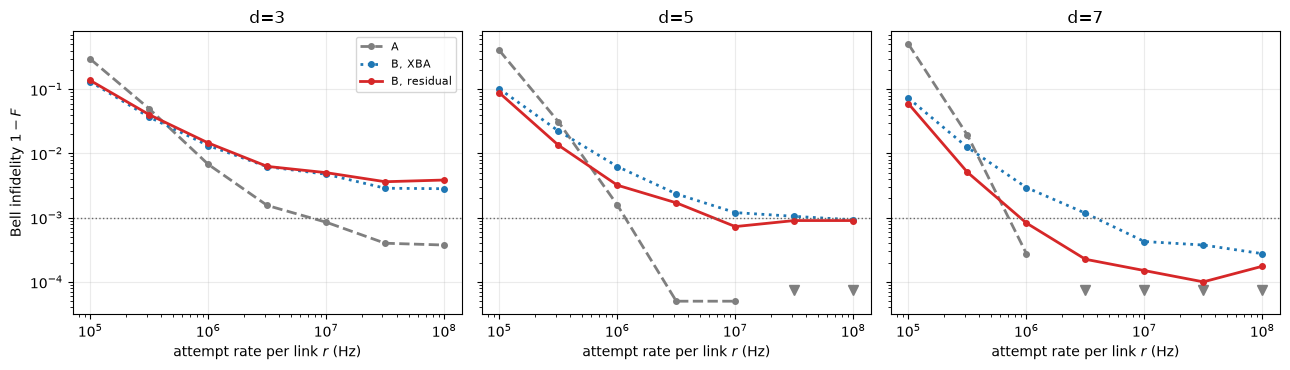

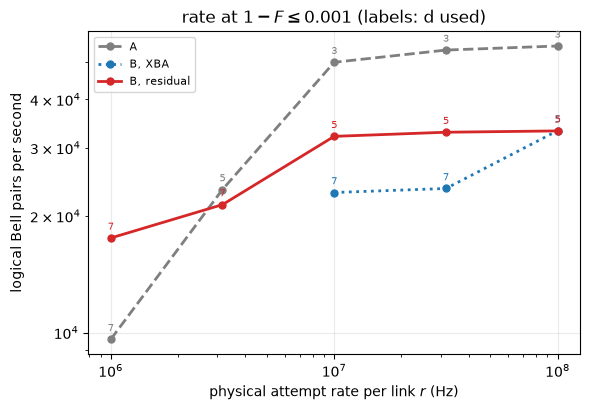

In [39]:
styles = {"A": ("C7", "--"), "B, XBA": ("C0", ":"), "B, residual": ("C3", "-")}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, d in zip(axes, DS):
    for name, (F, _) in curves.items():
        y = np.array([F(d, r) for r in rs])
        seen = y > 0
        c, ls = styles[name]
        ax.plot(rs[seen], y[seen], ls, marker="o", color=c, ms=4, lw=2, label=name)
        ax.plot(rs[~seen], np.full((~seen).sum(), 3 / RATE_SHOTS), "v", color=c, ms=7)
    ax.axhline(TARGET, color="0.4", ls=":", lw=1)
    ax.set(xscale="log", yscale="log", xlabel="attempt rate per link $r$ (Hz)", title=f"d={d}")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Bell infidelity $1-F$")
axes[0].legend(fontsize=8)
fig.tight_layout()

fig, ax = plt.subplots(figsize=(6, 4.2))
for name in curves:
    c, ls = styles[name]
    y = np.array([best2[name, r][1] for r in rs])
    ax.plot(rs, y, "o" + ls, color=c, ms=5, lw=2, label=name)
    for r in rs:
        d, val = best2[name, r]
        if d:
            ax.annotate(f"{d}", (r, val), textcoords="offset points", xytext=(0, 6), ha="center",
                        fontsize=7, color=c)
ax.set(xscale="log", yscale="log", xlabel="physical attempt rate per link $r$ (Hz)",
       ylabel="logical Bell pairs per second",
       title=f"rate at $1-F \\leq {TARGET:g}$ (labels: d used)")
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
fig.tight_layout()

### What residual targeting buys

* It raises the residual distance by about one at $d \ge 5$ (table above) and cuts B's infidelity by 2–4× at $d=7$, so B meets the target from $r = 10^6$ Hz instead of $10^7$.
* At $r = 10^6$ Hz both strategies need $d=7$, and B's rate is 1.8× A's: B waits one slot per merge layer, A waits for the slowest of up to 7 links, $\mathbb E[M_7] \approx 4.2$ slots.
* From $r \gtrsim 3\times10^6$ Hz waiting is negligible next to $6d\,t_r$, A meets the target at $d=3$ while B needs $d=5$, and B drops to about 0.6× A. With $T_\text{mem} = 1$ ms the window where waiting matters is almost entirely ruled out by memory noise, which motivates §18.

## 18. Where can B win? Sweep the memory lifetime

B's only advantage is time: one slot per merge layer instead of A's wait for the slowest link, $\mathbb E[M_m]\,\tau$. That dominates the time per pair only when $\tau \gg t_r$, i.e. at low $r$, and §17 shows that with $T_\text{mem} = 1$ ms memory noise rules out low $r$ for both strategies. So sweep $T_\text{mem} \in \{1, 10, 100\}$ ms and extend $r$ down to $10^3$ Hz, with B using the residual-targeting patterns of §17.

Every time enters only through $t_r/T_\text{mem}$ and $\tau/T_\text{mem}$, and the rate through $1/t_r$. So this is also a sweep of $t_r$ at fixed $T_\text{mem}$: the axes are effectively $T_\text{mem}/t_r$ and $r\,t_r$.

The full grid ($T_\text{mem}$, strategy, $d$, $r$) is decoded in parallel over forked workers, each setting its own `T_MEM`.

In [40]:
T_MEMS = (1e-3, 1e-2, 1e-1)
rs2 = np.logspace(3, 7, 9)
T_MEM_SAVED = T_MEM


keys = [(T, strategy, d, r) for T in T_MEMS for strategy in ("A", "B") for d in DS for r in rs2]
P = logical_errors([(T, d, obs, strategy, r, "res_patterns" if strategy == "B" else None,
                     int(1e5 * T) + 100 * j + 10 * d + k)
                    for T, strategy, d, r in keys for j in [list(rs2).index(r)]
                    for k, obs in enumerate(("ZZ", "XX"))])
infid_T = {key: 1 - (1 - P[2 * i]) * (1 - P[2 * i + 1]) for i, key in enumerate(keys)}
assert T_MEM == T_MEM_SAVED  # the workers set T_MEM, the kernel does not

sweep_T = {}  # (T_mem, strategy, r) -> (smallest d meeting the target, rate) or (None, nan)
for T, strategy, r in {(T, s_, r) for T, s_, _, r in keys}:
    ok = [d for d in DS if infid_T[T, strategy, d, r] <= TARGET]
    d = min(ok) if ok else None
    sweep_T[T, strategy, r] = ((d, rate("A", d, r) if strategy == "A" else rate_B(d, r, A_res[d]))
                               if d else (None, np.nan))

for T in T_MEMS:
    print(f"\nT_mem = {T * 1e3:g} ms")
    print(f"{'r (Hz)':>9}  {'A: d, rate':>16}  {'B: d, rate':>16}  {'B / A':>6}")
    for r in rs2:
        (da, ra), (db, rb) = sweep_T[T, "A", r], sweep_T[T, "B", r]
        ratio = rb / ra if ra == ra and rb == rb else (np.inf if rb == rb else np.nan)
        print(f"{r:>9.1e}  {str(da):>4} {ra:>11.3e}  {str(db):>4} {rb:>11.3e}  {ratio:>6.2f}")


T_mem = 1 ms
   r (Hz)        A: d, rate        B: d, rate   B / A
  1.0e+03  None         nan  None         nan     nan
  3.2e+03  None         nan  None         nan     nan
  1.0e+04  None         nan  None         nan     nan
  3.2e+04  None         nan  None         nan     nan
  1.0e+05  None         nan  None         nan     nan
  3.2e+05  None         nan  None         nan     nan
  1.0e+06     7   9.600e+03     7   1.754e+04    1.83
  3.2e+06     5   2.340e+04     7   2.139e+04    0.91
  1.0e+07     3   4.986e+04     5   3.210e+04    0.64

T_mem = 10 ms
   r (Hz)        A: d, rate        B: d, rate   B / A
  1.0e+03  None         nan  None         nan     nan
  3.2e+03  None         nan  None         nan     nan
  1.0e+04  None         nan  None         nan     nan
  3.2e+04  None         nan  None         nan     nan
  1.0e+05     7   1.507e+03     7   5.207e+03    3.46
  3.2e+05     3   1.204e+04     5   1.540e+04    1.28
  1.0e+06     3   2.593e+04     5   2.434e+04    0.94

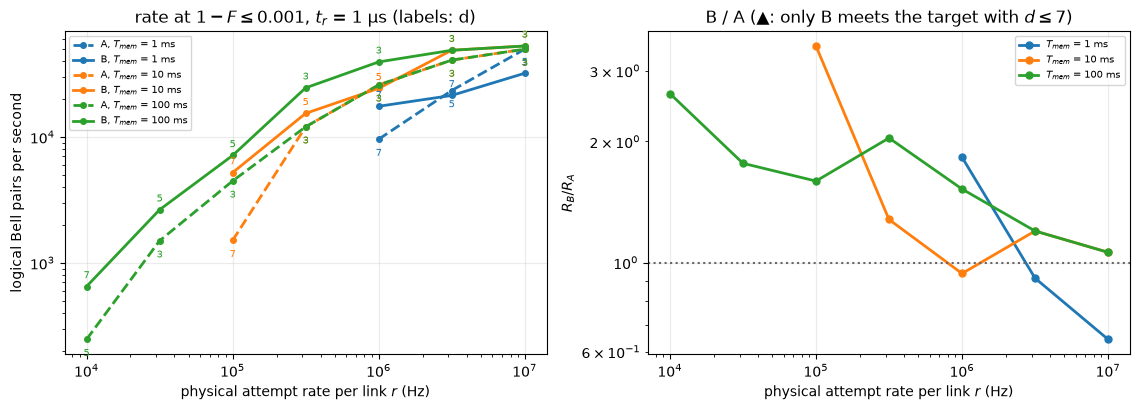

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
for c, T in enumerate(T_MEMS):
    for strategy, ls in (("A", "--"), ("B", "-")):
        y = np.array([sweep_T[T, strategy, r][1] for r in rs2])
        axes[0].plot(rs2, y, "o" + ls, color=f"C{c}", ms=4, lw=2,
                     label=f"{strategy}, $T_{{mem}}$ = {T * 1e3:g} ms")
        for r, (d, val) in ((r, sweep_T[T, strategy, r]) for r in rs2):
            if d:
                axes[0].annotate(f"{d}", (r, val), textcoords="offset points",
                                 xytext=(0, 6 if strategy == "B" else -12), ha="center", fontsize=7, color=f"C{c}")
    ratio = np.array([sweep_T[T, "B", r][1] / sweep_T[T, "A", r][1] for r in rs2])
    axes[1].plot(rs2, ratio, "o-", color=f"C{c}", ms=5, lw=2, label=f"$T_{{mem}}$ = {T * 1e3:g} ms")
    only_B = [r for r in rs2 if sweep_T[T, "B", r][0] and not sweep_T[T, "A", r][0]]
    axes[1].plot(only_B, np.full(len(only_B), 8.0), "^", color=f"C{c}", ms=8)
axes[1].axhline(1, color="0.4", ls=":", lw=1.5)
axes[0].set(xscale="log", yscale="log", xlabel="physical attempt rate per link $r$ (Hz)",
            ylabel="logical Bell pairs per second",
            title=f"rate at $1-F \\leq {TARGET:g}$, $t_r$ = 1 µs (labels: d)")
axes[1].set(xscale="log", yscale="log", xlabel="physical attempt rate per link $r$ (Hz)",
            ylabel="$R_B / R_A$", title="B / A (▲: only B meets the target with $d \\leq 7$)")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7)
fig.tight_layout()

### Where B wins

* **B wins wherever waiting is a large part of the time per pair and memory noise still allows a $d \le 7$ code.** With $T_\text{mem} = 100$ ms, $R_B/R_A$ is 1.5–2.6× for $r$ from $10^4$ to $10^6$ Hz. With $T_\text{mem} = 10$ ms it is 3.5× at $r = 10^5$ Hz, where A only just meets the target at $d=7$.
* **B loses only where it needs a larger $d$ than A.** That happens when the waits are already short ($T_\text{mem} = 1$ ms at $r \ge 3\times10^6$ Hz, 10 ms at $10^6$ Hz), and the erasures B accepts cost it a code size. When both use the same $d$, B is ahead (1.06–2×), because its slots are shorter and $A_d \approx 1$.
* The ratio is not monotonic in $r$ because $d$ moves in steps of 2 for each strategy separately. Near the target, the choice of $d$ is also subject to shot noise (40 000 shots gives about ±16% at $10^{-3}$).
* Caveats, all of which favour A: A's memory noise uses the *mean* wait (the logical error is convex in the wait), $d$ is capped at 7, and $\ell = 0$.

## Next steps

* Acceptance threshold on residual distance ($\delta > 1$) on top of the residual-targeting policy, tuned per $d$ and $r$.
* Sensitivity to the target and $\ell > 0$; $d > 7$ where neither strategy meets the target.